# 09 · Actual COSMO-RS liquid calculations and HANNA setup

The main course uses actual ThermoWeave models and real chemical components. See the [course index](../tutorials.md).

<a class="md-button" href="09_cosmors_and_hanna.ipynb" download>Download notebook</a>


This notebook executes real COSMO-RS water/ethanol activities using external
Turbomole conformers and the engine's `default_turbomole` parametrization.
Set `THERMOWEAVE_COSMO_ROOT` and, if needed, `THERMOWEAVE_OPENCOSMORS_BUILD`
as described in notebook 12. The saved outputs are real backend evaluations;
a new run requires actual inputs. The core algorithm demonstrations are in
the SAFT notebooks, which need no external COSMO files.

See the [portable setup guide](../models/opencosmors.md) for backend installation,
OS differences, database paths, parametrizations and a short verification command.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import build_cosmors_model,HannaModel
from _support import cosmo_components
names=['water','ethanol'];T=298.15
components,manifest=cosmo_components(names)
parameter_source=os.environ.get('THERMOWEAVE_COSMO_PARAMETERS','default_turbomole')
model=build_cosmors_model(parameter_source,components)
x=np.array([.8,.2])
print('Actual COSMO input manifest:',manifest)
print('Actual COSMO-RS ln gamma:',model.ln_activity_coefficients(T,x))
print('Activities:',model.activities(T,x))
print('gE/RT:',model.reduced_excess_gibbs(T,x))
X=np.array([[.8,.2],[.5,.5],[.2,.8]])
np.testing.assert_allclose(model.ln_activity_coefficients_batch(T,X),
                           np.array([model.ln_activity_coefficients(T,z) for z in X]),atol=2e-5)


BINARY SPECS
-------------------------
 compile mode: RELEASE
       openmp: activated
vectorization: AVX
-------------------------

Actual COSMO input manifest: [{'name': 'water', 'basis': 'COSMO_TZVPD_FINE', 'conformers': [{'file': 'H2O_c000.cosmo', 'sha256': '2d46cfea8920ed3770e91a4cf3dcc4720205e8b6483d4be834b832a0da6df44a'}]}, {'name': 'ethanol', 'basis': 'COSMO_TZVPD_FINE', 'conformers': [{'file': 'C2H6O_001_ethanol_CnfS1_c000.cosmo', 'sha256': '4c848f182351b681256edf70c609ef51f643b99c52ff5ad45ee53b9ebab333ce'}, {'file': 'C2H6O_001_ethanol_CnfS1_c001.cosmo', 'sha256': '121a8e463a3d1b9e32cdea31309026106708960f948489d821b7b2281469c5b8'}]}]
loadMolecules for every molecule worked...
Actual COSMO-RS ln gamma: [0.13311575 0.82426814]
Activities: [0.91390577 0.45604227]
gE/RT: 0.2713462250989705


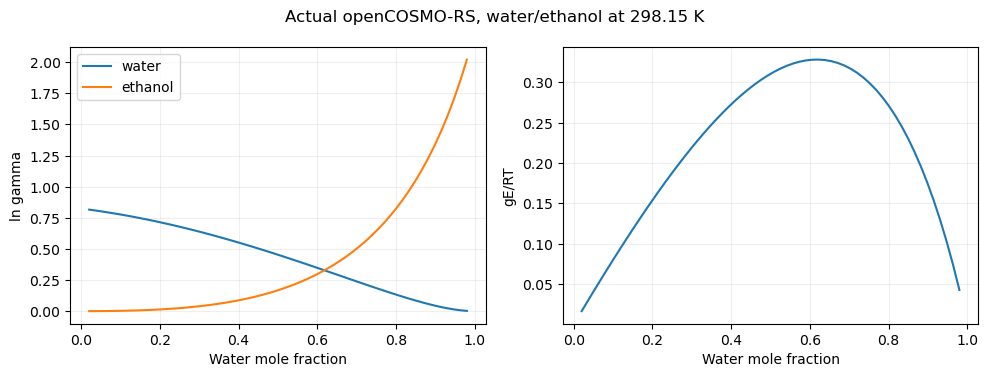

In [2]:
xs=np.linspace(.02,.98,60);X=np.column_stack([xs,1-xs])
lng=model.ln_activity_coefficients_batch(T,X)
fig,ax=plt.subplots(1,2,figsize=(10,3.8))
ax[0].plot(xs,lng[:,0],label='water');ax[0].plot(xs,lng[:,1],label='ethanol');ax[0].set_ylabel('ln gamma')
ax[1].plot(xs,np.sum(X*lng,axis=1));ax[1].set_ylabel('gE/RT')
for a in ax:a.set_xlabel('Water mole fraction');a.grid(alpha=.2)
ax[0].legend();fig.suptitle('Actual openCOSMO-RS, water/ethanol at 298.15 K');fig.tight_layout();plt.show()

## Use the actual HANNA adapter when its assets are installed
The call below uses HANNA directly. Missing assets are not replaced with
synthetic predictions. Set `HANNA_ROOT` and install the upstream dependencies
and weights in this notebook's Python environment. The optional block is
explicitly separate from the executed COSMO-RS calculations above.

In [3]:
hanna_root=os.environ.get('HANNA_ROOT')
if hanna_root:
    os.environ.setdefault('HF_HUB_OFFLINE','1')
    hanna=HannaModel(['O','CCO'],hanna_root=hanna_root)
    print('Actual HANNA ln gamma:',hanna.ln_activity_coefficients(T,x))
    print('Actual HANNA gE/RT:',hanna.reduced_excess_gibbs(T,x))
else:
    print('HANNA block not executed: its external model assets are not configured.')

HANNA block not executed: its external model assets are not configured.


Pass either real liquid model to `ReducedHELD` with consistent fusion data
and candidate solids. Notebook 12 executes that complete binary and ternary
SLLE workflow with COSMO-RS. Neither activity adapter supplies a PVT EOS;
use SAFT for density/pressure calculations.